In [9]:
def t():
    temp=int(input("enter t : "))
    return temp
def m():
    motion=input("")
    return motion

def home(temp,motion):
    if motion=="yes":
        a1="light ON"
        m1="entry"
    else:
        a1="off"
        m1 ="no one"

    if temp >30 :
        a2="ac on"
        m2="hottt"
    elif temp<5 :
        a2="heater on"
        m2="cold"
    else:
        a2="nothing"
        m2="nooo"
        
    return a1,a2,m1,m2

def actuator1(a1):
    print( a1)
def actuator2(a2):
    print( a2)
def message1(m1):
    print( m1)
def message2(m2):
    print( m2)

temperature = t()
motionn=m()

a1,a2,m1,m2=home(temperature ,motionn)
actuator1(a1)
message1(m1)

actuator2(a2)
message2(m2)


enter t :  22
 yes


light ON
entry
nothing
nooo


In [19]:

# Import deque to create a queue for BFS
from collections import deque

# Maze representation:
# 0 = Free path
# 1 = Wall (blocked path)
maze = [
    [0, 0, 0, 1, 0],
    [1, 0, 0, 1, 0],
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
]

# Starting position and destination
start = (0, 0)
goal = (4, 4)


# ---------------- BREADTH FIRST SEARCH (BFS) ----------------

def bfs(start, goal):

    # Queue stores complete paths; initially, only start is present
    queue = deque([[start]])

    # Store visited positions to avoid revisiting cells
    visited = [start]

    # Continue until the queue becomes empty
    while queue:

        # Remove the oldest path from the queue (FIFO)
        path = queue.popleft()

        # Get the last position in the current path
        row, col = path[-1]

        # If destination is reached, return the path
        if (row, col) == goal:
            return path

        # Generate neighboring cells: up, down, left, right
        neighbors = [
            (row - 1, col),  # Up
            (row + 1, col),  # Down
            (row, col - 1),  # Left
            (row, col + 1)   # Right
        ]

        # Check every neighboring cell
        for r, c in neighbors:

            # Ensure the position is inside the 5x5 maze
            if 0 <= r < 5 and 0 <= c < 5:

                # Move only through free cells that are not visited
                if maze[r][c] == 0 and (r, c) not in visited:

                    # Mark the cell as visited
                    visited.append((r, c))

                    # Add the new position to the existing path
                    queue.append(path + [(r, c)])

    # Return an empty path if the goal cannot be reached
    return []


# Run BFS and display the result
print("BREADTH FIRST SEARCH")

path = bfs(start, goal)

print("Path:", path)
print("Path Length:", len(path) - 1)


# ---------------- DEPTH FIRST SEARCH (DFS) ----------------

def dfs(start, goal):

    # Stack stores complete paths; initially, only start is present
    stack = [[start]]

    # Store visited positions to avoid revisiting cells
    visited = [start]

    # Continue until the stack becomes empty
    while stack:

        # Remove the most recently added path (LIFO)
        path = stack.pop()

        # Get the last position in the current path
        row, col = path[-1]

        # If destination is reached, return the path
        if (row, col) == goal:
            return path

        # Generate neighboring cells: up, down, left, right
        neighbors = [
            (row - 1, col),  # Up
            (row + 1, col),  # Down
            (row, col - 1),  # Left
            (row, col + 1)   # Right
        ]

        # Check every neighboring cell
        for r, c in neighbors:

            # Ensure the position is inside the 5x5 maze
            if 0 <= r < 5 and 0 <= c < 5:

                # Move only through free cells that are not visited
                if maze[r][c] == 0 and (r, c) not in visited:

                    # Mark the cell as visited
                    visited.append((r, c))

                    # Push the extended path onto the stack
                    stack.append(path + [(r, c)])

    # Return an empty path if the goal cannot be reached
    return []


# Run DFS and display the result
print("DEPTH FIRST SEARCH")

path = dfs(start, goal)

print("Path:", path)
print("Path Length:", len(path) - 1)


BREADTH FIRST SEARCH
Path: [(0, 0), (0, 1), (1, 1), (2, 1), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]
Path Length: 8
DEPTH FIRST SEARCH
Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]
Path Length: 8


In [1]:
import heapq
# PR3(b): A* Search and Greedy Best-First Search

# Maze representation:
# 0 = Free cell
# 1 = Wall
maze = [
    [0, 0, 0, 1, 0],
    [1, 0, 0, 1, 0],
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
]

# Define the starting position and goal position
start = (0, 0)
goal = (4, 2)


# Calculate Manhattan distance from a position to the goal
def heuristic(position):
    return abs(position[0] - goal[0]) + abs(position[1] - goal[1])


# ---------------- A* SEARCH ALGORITHM ----------------

def a_star(start, goal):

    # Store (estimated total cost, complete path)
    # Initially, the path contains only the start position
    queue = [(heuristic(start), [start])]

    # Store positions that have already been explored
    visited = []

    # Continue while paths are available
    while queue:

        # Sort paths by cost in descending order
        # pop() removes the last item, which has the lowest cost
        queue.sort(reverse=True)

        cost, path = queue.pop()

        # Get the current position from the end of the path
        row, col = path[-1]

        # If the goal is reached, return the path
        if (row, col) == goal:
            return path

        # Explore this position only if it was not visited
        if (row, col) not in visited:
            visited.append((row, col))

            # Generate neighboring positions
            neighbors = [
                (row - 1, col),  # Up
                (row + 1, col),  # Down
                (row, col - 1),  # Left
                (row, col + 1)   # Right
            ]

            # Check all neighboring positions
            for r, c in neighbors:

                # Check whether the position is inside the maze
                if 0 <= r < 5 and 0 <= c < 5:

                    # Allow only free and unvisited cells
                    if maze[r][c] == 0 and (r, c) not in visited:

                        # Create a new path by adding the neighbor
                        new_path = path + [(r, c)]

                        # g(n) = actual number of moves so far
                        g = len(new_path) - 1

                        # h(n) = estimated distance to the goal
                        h = heuristic((r, c))

                        # A* evaluation function: f(n) = g(n) + h(n)
                        cost = g + h

                        # Add the new path and its cost to the queue
                        queue.append((cost, new_path))

    # Return an empty path if the goal cannot be reached
    return []


print("A* SEARCH")

path = a_star(start, goal)

print("Path:", path)
print("Path Length:", len(path) - 1)


# ---------------- GREEDY BEST-FIRST SEARCH ----------------

def greedy_search(start, goal):

    # Store (heuristic value, complete path)
    # Greedy search considers only the estimated distance to the goal
    queue = [(heuristic(start), [start])]

    # Mark the starting position as visited
    visited = [start]

    # Continue while paths are available
    while queue:

        # Sort by heuristic value in descending order
        # pop() selects the path with the lowest heuristic value
        queue.sort(reverse=True)

        priority, path = queue.pop()

        # Get the current position
        row, col = path[-1]

        # If the goal is reached, return the path
        if (row, col) == goal:
            return path

        # Generate neighboring positions
        neighbors = [
            (row - 1, col),  # Up
            (row + 1, col),  # Down
            (row, col - 1),  # Left
            (row, col + 1)   # Right
        ]

        # Check each neighboring position
        for r, c in neighbors:

            # Ensure the position is inside the maze
            if 0 <= r < 5 and 0 <= c < 5:

                # Check that the cell is free and not visited
                if maze[r][c] == 0 and (r, c) not in visited:

                    # Mark the cell visited when adding it to the queue
                    visited.append((r, c))

                    # Extend the current path
                    new_path = path + [(r, c)]

                    # Greedy priority = heuristic only
                    priority = heuristic((r, c))

                    # Add the path to the queue
                    queue.append((priority, new_path))

    # Return an empty path if the goal cannot be reached
    return []


print("GREEDY BEST-FIRST SEARCH")

path = greedy_search(start, goal)

print("Path:", path)
print("Path Length:", len(path) - 1)


A* SEARCH
Path: [(0, 0), (0, 1), (1, 1), (2, 1), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2)]
Path Length: 8
GREEDY BEST-FIRST SEARCH
Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 1), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2)]
Path Length: 10


In [3]:
# PR4: Rule-Based Expert System
# Demonstration of Forward Chaining and Backward Chaining

# Step 1: Store the initial fact.
# Initially, we know that it is raining.
facts = {"raining"}

# Step 2: Define the rules of the expert system.
# Each key is a conclusion, and its value contains the required conditions.
rules = {
    "ground_wet": ["raining"],
    "ground_slippery": ["ground_wet"]
}


# Step 3: Define the Forward Chaining function.
# Forward chaining starts with known facts and derives new conclusions.
def forward_chaining(facts, rules):

    # Create a copy of the initial facts to avoid changing the original set.
    facts = set(facts)

    # This variable tells us whether any new fact was derived.
    changed = True

    # Repeat until no new facts can be derived.
    while changed:
        changed = False

        # Check each rule in the rule base.
        for conclusion, conditions in rules.items():

            # Check whether all conditions of the rule are satisfied.
            if all(condition in facts for condition in conditions):

                # Add the conclusion only if it is not already known.
                if conclusion not in facts:
                    facts.add(conclusion)
                    print("Derived:", conclusion)

                    # A new fact was added, so another pass may be needed.
                    changed = True

    # Return all the initial and newly derived facts.
    return facts


# Step 4: Define the Backward Chaining function.
# Backward chaining starts with a goal and checks whether it can be proved.
def backward_chaining(goal, facts, rules):

    # If the goal is already a known fact, it is proved.
    if goal in facts:
        return True

    # If no rule can establish the goal, it cannot be proved.
    if goal not in rules:
        return False

    # Check every condition required to prove the goal.
    for condition in rules[goal]:

        # Recursively check whether the condition can be proved.
        if not backward_chaining(condition, facts, rules):
            return False

    # If all required conditions are proved, the goal is proved.
    return True


# Step 5: Display the initial fact.
print("Initial Fact: It is raining")


# Step 6: Apply Forward Chaining.
print("\nForward Chaining:")

# Derive all possible facts using the available rules.
all_facts = forward_chaining(facts, rules)

# Display the final set of facts.
print("Final Facts:", all_facts)


# Step 7: Apply Backward Chaining.
print("\nBackward Chaining:")

# Specify the goal that we want to prove.
goal = "ground_slippery"

# Check whether the goal can be proved from the initial facts and rules.
if backward_chaining(goal, facts, rules):
    print("Goal proved: Ground is slippery")
else:
    print("Goal cannot be proved")

Initial Fact: It is raining

Forward Chaining:
Derived: ground_wet
Derived: ground_slippery
Final Facts: {'ground_wet', 'raining', 'ground_slippery'}

Backward Chaining:
Goal proved: Ground is slippery


         survived         age         sex        fare
count  762.000000  762.000000  762.000000  762.000000
mean     0.416010   29.604226    0.622047   35.166617
std      0.493219   13.839533    0.485194   52.754631
min      0.000000    0.420000    0.000000    0.000000
25%      0.000000   21.000000    0.000000    8.050000
50%      0.000000   28.000000    1.000000   16.050000
75%      1.000000   36.000000    1.000000   34.375000
max      1.000000   80.000000    1.000000  512.329200


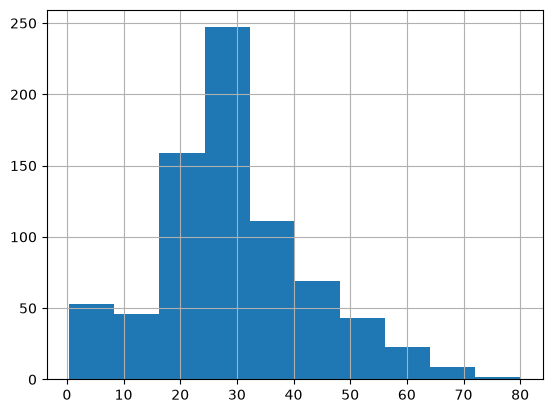

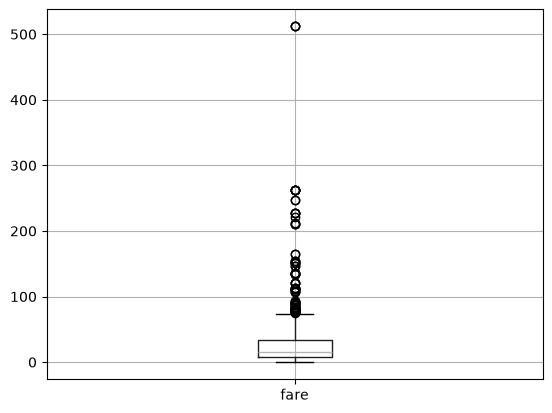

Training size: (609, 3)
Testing size: (153, 3)
Preprocessing completed!


In [21]:

# PR5: Data Preprocessing and Exploratory Data Analysis (EDA)

# Import Seaborn to load the Titanic dataset
# and create statistical visualizations if required
import seaborn as sns

# Import Pandas to store and manipulate tabular data
import pandas as pd

# Import Matplotlib to display graphs
import matplotlib.pyplot as plt

# Import the function to divide data into training and testing sets
from sklearn.model_selection import train_test_split

# Import LabelEncoder to convert categorical labels into numbers
# Import StandardScaler to standardize numerical features
from sklearn.preprocessing import LabelEncoder, StandardScaler


# Step 1: Load the Titanic dataset
# The dataset contains passenger information and survival details
df = sns.load_dataset("titanic")


# Step 2: Select the required columns
# survived = 0 means did not survive; 1 means survived
# age = passenger's age
# sex = passenger's sex
# fare = ticket fare
df = df[["survived", "age", "sex", "fare"]]


# Step 3: Handle missing values in the age column
# median() calculates the middle age value
# fillna() replaces missing age values with the median
df["age"] = df["age"].fillna(df["age"].median())


# Step 4: Remove duplicate rows
# drop_duplicates() removes repeated rows
df = df.drop_duplicates()


# Step 5: Encode categorical data
# Create a LabelEncoder object
le = LabelEncoder()

# Convert the sex column from text labels into numbers
# Typically, female = 0 and male = 1
df["sex"] = le.fit_transform(df["sex"])


# Step 6: Perform statistical analysis
# describe() displays count, mean, standard deviation,
# minimum, maximum and quartile values
print(df.describe())


# Step 7: Draw a histogram of passenger ages
# A histogram shows the distribution of numerical values
df["age"].hist()

# Display the histogram
plt.show()


# Step 8: Draw a boxplot of ticket fares
# A boxplot shows the median, quartiles and potential outliers
df.boxplot(column="fare")

# Display the boxplot
plt.show()


# Step 9: Perform feature scaling
# Create a StandardScaler object
scaler = StandardScaler()

# Standardize age and fare so that each has
# approximately mean 0 and standard deviation 1
df[["age", "fare"]] = scaler.fit_transform(df[["age", "fare"]])


# Step 10: Separate input features and target
# X contains the columns used to make predictions
X = df.drop("survived", axis=1)

# y contains the outcome we want to predict
y = df["survived"]


# Step 11: Split the data into training and testing sets
# 80% of the data is used for training
# 20% of the data is used for testing
# random_state=42 makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# Step 12: Display the dimensions of the resulting datasets
# shape returns (number of rows, number of columns)
print("Training size:", X_train.shape)
print("Testing size:", X_test.shape)


# Display a completion message
print("Preprocessing completed!")


Linear Regression
MSE: 0.555891598695242
MAE: 0.5332001304956983
R2 Score: 0.5757877060324526

Polynomial Regression
MSE: 0.6045383165381668
MAE: 0.5161833692971958
R2 Score: 0.5386643967063607


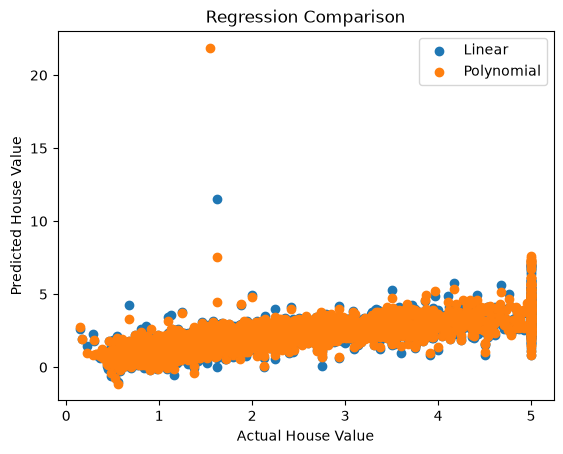

In [22]:

# PR: Comparison of Linear Regression and Polynomial Regression

# Import Matplotlib for plotting graphs
import matplotlib.pyplot as plt

# Import the California Housing dataset
from sklearn.datasets import fetch_california_housing

# Import the function to split data into training and testing sets
from sklearn.model_selection import train_test_split

# Import the Linear Regression algorithm
from sklearn.linear_model import LinearRegression

# Import PolynomialFeatures to create polynomial input features
from sklearn.preprocessing import PolynomialFeatures

# Import make_pipeline to combine preprocessing and a model
from sklearn.pipeline import make_pipeline

# Import evaluation metrics to measure prediction errors and model fit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# Step 1: Load the California Housing dataset
data = fetch_california_housing()

# Store the input features in X
# These include income, house age, rooms, population and other features
X = data.data

# Store the target house value in y
y = data.target


# Step 2: Split the dataset into training and testing sets
# 80% is used for training and 20% for testing
# random_state=42 makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# Step 3: Create the Linear Regression model
linear_model = LinearRegression()

# Train the model using the training data
linear_model.fit(X_train, y_train)

# Predict house values for the testing data
linear_pred = linear_model.predict(X_test)


# Step 4: Create the Polynomial Regression model
# PolynomialFeatures(degree=2) adds squared terms
# and interaction terms between input features
# LinearRegression then learns from the expanded features
polynomial_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

# Train the polynomial model
polynomial_model.fit(X_train, y_train)

# Predict house values using the polynomial model
polynomial_pred = polynomial_model.predict(X_test)


# Step 5: Evaluate Linear Regression
print("Linear Regression")

# MSE: Mean Squared Error; penalizes large errors more strongly
print("MSE:", mean_squared_error(y_test, linear_pred))

# MAE: Mean Absolute Error; average absolute prediction error
print("MAE:", mean_absolute_error(y_test, linear_pred))

# R2 Score: Measures how well predictions explain target variation
print("R2 Score:", r2_score(y_test, linear_pred))


# Step 6: Evaluate Polynomial Regression
print("\nPolynomial Regression")

# Calculate Mean Squared Error
print("MSE:", mean_squared_error(y_test, polynomial_pred))

# Calculate Mean Absolute Error
print("MAE:", mean_absolute_error(y_test, polynomial_pred))

# Calculate R-squared score
print("R2 Score:", r2_score(y_test, polynomial_pred))


# Step 7: Compare actual and predicted house values
# Actual values are on the X-axis
# Predicted values are on the Y-axis
plt.scatter(y_test, linear_pred, label="Linear")

# Plot the predictions from Polynomial Regression
plt.scatter(y_test, polynomial_pred, label="Polynomial")

# Label the horizontal axis
plt.xlabel("Actual House Value")

# Label the vertical axis
plt.ylabel("Predicted House Value")

# Add a title to the graph
plt.title("Regression Comparison")

# Display the legend to distinguish both models
plt.legend()

# Display the graph
plt.show()


Logistic Regression Accuracy: 1.0
KNN Accuracy: 0.9444444444444444


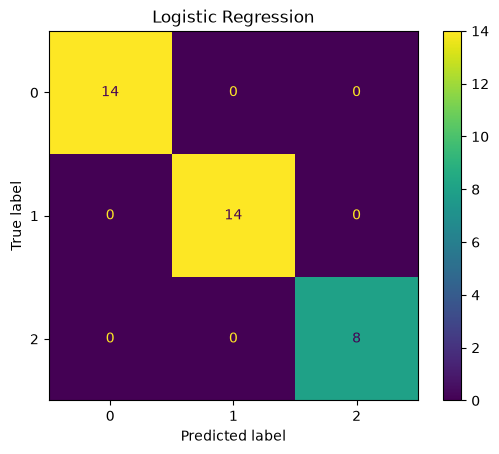

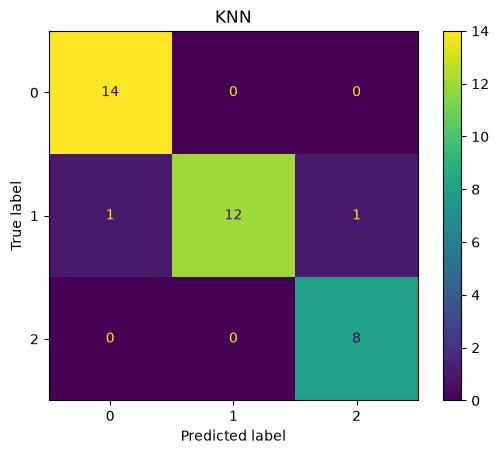

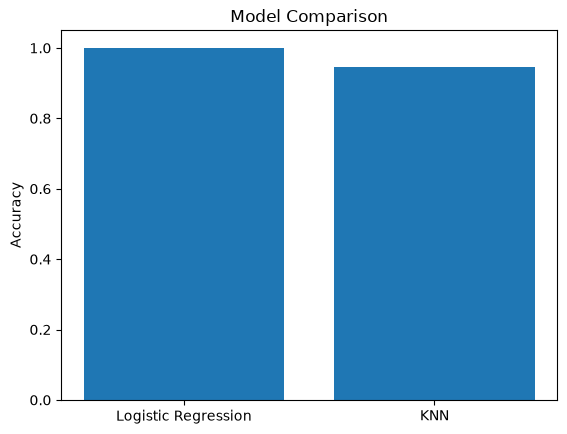

In [27]:

# PR7: Classification using Logistic Regression and KNN
# Aim: Classify wine samples into different classes and compare both models.

# Import Matplotlib to display graphs
import matplotlib.pyplot as plt

# Import the built-in Wine dataset from Scikit-learn
from sklearn.datasets import load_wine

# Import the function to split data into training and testing sets
from sklearn.model_selection import train_test_split

# Import StandardScaler to standardize numerical features
from sklearn.preprocessing import StandardScaler

# Import Logistic Regression classification algorithm
from sklearn.linear_model import LogisticRegression

# Import the K-Nearest Neighbors classification algorithm
from sklearn.neighbors import KNeighborsClassifier

# Import accuracy and confusion matrix evaluation tools
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


# Step 1: Load the Wine dataset
data = load_wine()

# Store the input features in X
# These include alcohol, malic acid, ash and other wine measurements
X = data.data

# Store the target class labels in y
# The dataset contains three wine classes: 0, 1 and 2
y = data.target


# Step 2: Split the dataset into training and testing sets
# 80% of the data is used for training and 20% for testing
# random_state=42 makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# Step 3: Standardize the input features
# StandardScaler creates features with mean approximately 0
# and standard deviation approximately 1
scaler = StandardScaler()

# Learn scaling values from training data and transform it
X_train = scaler.fit_transform(X_train)

# Apply the same scaling values to testing data
# Do not fit the scaler again on testing data
X_test = scaler.transform(X_test)


# Step 4: Create the Logistic Regression model
# max_iter=5000 allows more iterations for model convergence
lr = LogisticRegression(max_iter=5000)

# Train the model using the scaled training data
lr.fit(X_train, y_train)

# Predict the wine classes for the testing data
lr_pred = lr.predict(X_test)


# Step 5: Create the K-Nearest Neighbors model
# n_neighbors=5 means it considers the five nearest training samples
knn = KNeighborsClassifier(n_neighbors=5)

# Train the KNN model using the scaled training data
knn.fit(X_train, y_train)

# Predict the wine classes for the testing data
knn_pred = knn.predict(X_test)


# Step 6: Calculate and display model accuracy
# Accuracy is the proportion of correct predictions
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred))

print("KNN Accuracy:",
      accuracy_score(y_test, knn_pred))


# Step 7: Create confusion matrices for both models
# Rows represent actual classes and columns represent predicted classes
cm1 = confusion_matrix(y_test, lr_pred)
cm2 = confusion_matrix(y_test, knn_pred)


# Display the confusion matrix for Logistic Regression
ConfusionMatrixDisplay(cm1).plot()

# Add a title to the graph
plt.title("Logistic Regression")

# Display the graph
plt.show()


# Display the confusion matrix for KNN
ConfusionMatrixDisplay(cm2).plot()

# Add a title to the graph
plt.title("KNN")

# Display the graph
plt.show()


# Step 8: Compare the accuracy of both models using a bar graph
plt.bar(
    ["Logistic Regression", "KNN"],
    [accuracy_score(y_test, lr_pred), accuracy_score(y_test, knn_pred)]
)

# Label the vertical axis
plt.ylabel("Accuracy")

# Add the graph title
plt.title("Model Comparison")

# Display the comparison graph
plt.show()



 Decision Tree
Accuracy: 0.9473684210526315
Precision: 0.9577464788732394
Recall: 0.9577464788732394
F1 Score: 0.9577464788732394
Confusion Matrix:
[[40  3]
 [ 3 68]]

 Naive Bayes
Accuracy: 0.9736842105263158
Precision: 0.9594594594594594
Recall: 1.0
F1 Score: 0.9793103448275862
Confusion Matrix:
[[40  3]
 [ 0 71]]

Classification completed!


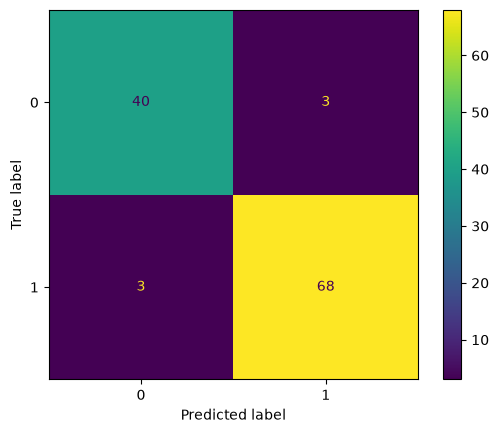

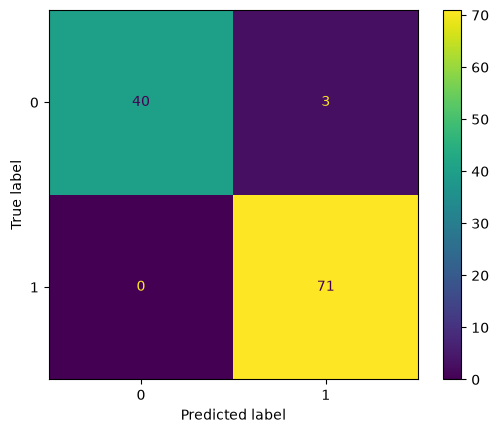

In [33]:
from sklearn.datasets import load_breast_cancer 
from sklearn.model_selection import train_test_split 
from sklearn.tree import DecisionTreeClassifier 
from sklearn.naive_bayes import GaussianNB 
from sklearn.metrics import ( 
    accuracy_score, precision_score, 
    recall_score, f1_score, confusion_matrix 
) 
 
# Load dataset 
data = load_breast_cancer() 
X = data.data 
y = data.target 
 
# Split dataset 
X_train, X_test, y_train, y_test = train_test_split( 
    X, y, test_size=0.2, random_state=42 
) 
 
# Create models 
models = { 
    "Decision Tree": DecisionTreeClassifier(random_state=42), 
    "Naive Bayes": GaussianNB() 
} 
 
# Train and evaluate models 
for name, model in models.items(): 
    model.fit(X_train, y_train) 
    y_pred = model.predict(X_test) 
 
    print("\n", name) 
    print("Accuracy:", accuracy_score(y_test, y_pred)) 
    print("Precision:", precision_score(y_test, y_pred)) 
    print("Recall:", recall_score(y_test, y_pred)) 
    print("F1 Score:", f1_score(y_test, y_pred)) 
    print("Confusion Matrix:") 
    print(confusion_matrix(y_test, y_pred))
    cm=confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm).plot()
    
 
print("\nClassification completed!")

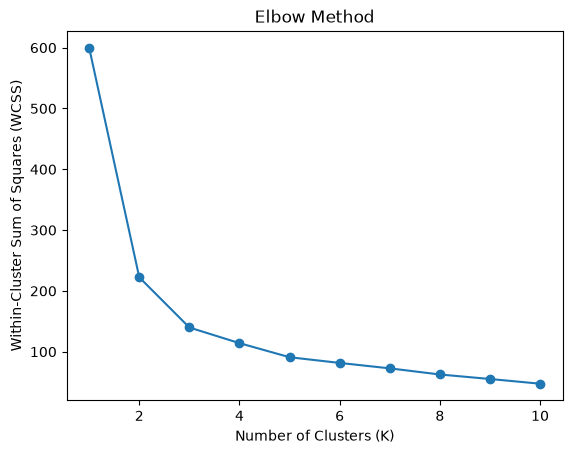

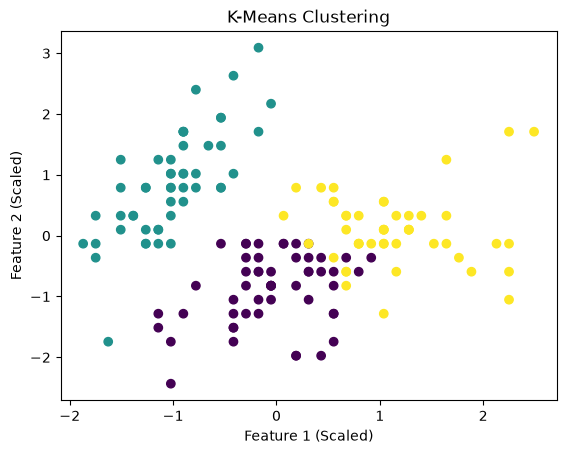

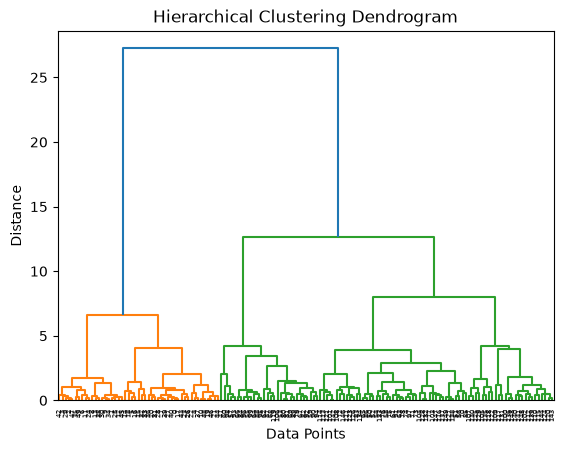

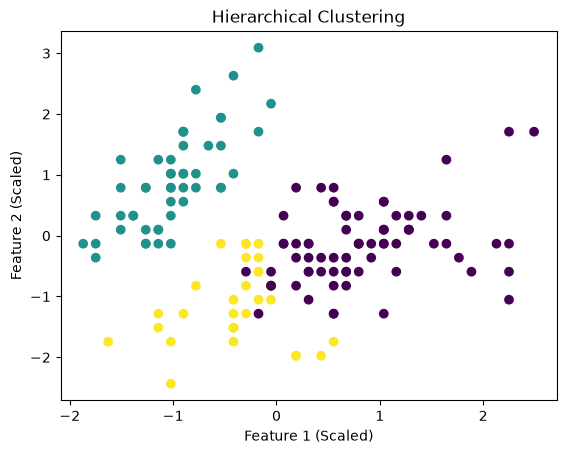

K-Means cluster counts:
[np.int64(53), np.int64(50), np.int64(47)]

Hierarchical cluster counts:
[np.int64(71), np.int64(49), np.int64(30)]

Clustering completed!


In [39]:

# PR9: Clustering Techniques
# Algorithms: K-Means and Hierarchical Clustering
# Methods: Elbow Method and Dendrogram

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage

# Step 1: Load the Iris dataset
data = load_iris()
X = data.data

# Step 2: Scale the features so they have a similar scale
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Step 3: Apply the Elbow Method to find a suitable
# number of clusters for K-Means
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X)

    # Store the Within-Cluster Sum of Squares
    wcss.append(model.inertia_)

# Plot the Elbow graph
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.show()

# Step 4: Apply K-Means clustering with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model and obtain cluster labels
k_labels = kmeans.fit_predict(X)

# Plot the clusters using the first two features
plt.scatter(X[:, 0], X[:, 1], c=k_labels)
plt.title("K-Means Clustering")
plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.show()

# Step 5: Create a linkage matrix for hierarchical clustering
# Ward's method combines clusters while minimizing
# the increase in within-cluster variance
linked = linkage(X, method="ward")

# Display the Dendrogram
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

# Step 6: Apply Agglomerative Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=3)

# Fit the model and obtain cluster labels
h_labels = hc.fit_predict(X)

# Plot the hierarchical clusters using the first two features
plt.scatter(X[:, 0], X[:, 1], c=h_labels)
plt.title("Hierarchical Clustering")
plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.show()

# Step 7: Display the number of data points in each cluster
print("K-Means cluster counts:")
print([sum(k_labels == i) for i in range(3)])

print("\nHierarchical cluster counts:")
print([sum(h_labels == i) for i in range(3)])

print("\nClustering completed!")


Accuracy before PCA: 1.0
Accuracy after PCA: 1.0
Features before PCA: 13
Features after PCA: 2
Explained variance ratio: [0.35900066 0.18691934]
Total variance retained: 0.5459200022286599


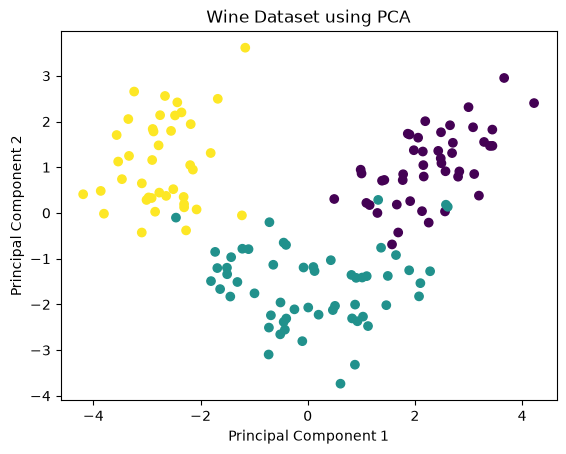

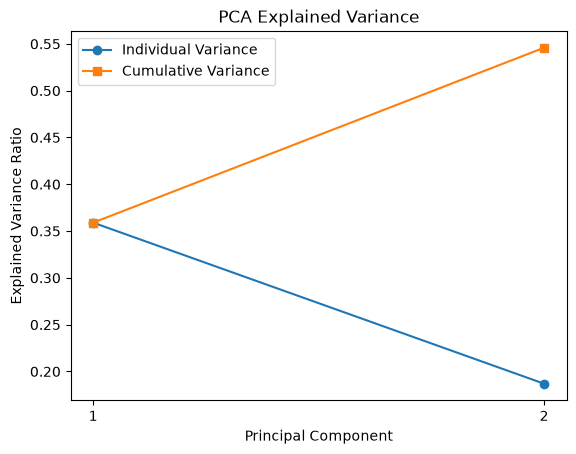


PCA dimensionality reduction completed!


In [40]:

# PR10: Dimensionality Reduction using PCA
# Algorithm:
# 1. Load the Wine dataset.
# 2. Split the dataset into training and testing sets.
# 3. Standardize the features.
# 4. Apply PCA to reduce 13 features to 2 components.
# 5. Train Logistic Regression before and after PCA.
# 6. Compare accuracy and visualize the results.

import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Step 1: Load the Wine dataset
data = load_wine()

# X contains the input features; y contains the target classes
X = data.data
y = data.target

# Step 2: Split the data into training and testing sets
# 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 3: Standardize the features
# Fit the scaler only on training data to avoid data leakage
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 4: Train Logistic Regression before PCA
model1 = LogisticRegression(max_iter=5000)
model1.fit(X_train, y_train)

# Predict the test data and calculate accuracy
pred1 = model1.predict(X_test)
accuracy_before = accuracy_score(y_test, pred1)

print("Accuracy before PCA:", accuracy_before)

# Step 5: Apply PCA to reduce 13 features to 2 components
# Fit PCA only on the training data
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)

# Transform the test data using the same PCA model
X_test_pca = pca.transform(X_test)

# Step 6: Train Logistic Regression after PCA
model2 = LogisticRegression(max_iter=5000)
model2.fit(X_train_pca, y_train)

# Predict the test data and calculate accuracy
pred2 = model2.predict(X_test_pca)
accuracy_after = accuracy_score(y_test, pred2)

print("Accuracy after PCA:", accuracy_after)

# Display the number of features before and after PCA
print("Features before PCA:", X_train.shape[1])
print("Features after PCA:", X_train_pca.shape[1])

# Display the variance explained by the two components
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:",
      sum(pca.explained_variance_ratio_))

# Step 7: Visualize the training data using the first two components
plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Dataset using PCA")
plt.show()

# Step 8: Plot individual and cumulative explained variance
explained = pca.explained_variance_ratio_
cumulative = explained.cumsum()

plt.plot(
    range(1, len(explained) + 1),
    explained,
    marker="o",
    label="Individual Variance"
)
plt.plot(
    range(1, len(cumulative) + 1),
    cumulative,
    marker="s",
    label="Cumulative Variance"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.xticks([1, 2])
plt.legend()
plt.show()

print("\nPCA dimensionality reduction completed!")


SVM Accuracy Before: 1.0
Best Parameters: {'svc__C': 1, 'svc__kernel': 'rbf'}
Best Cross-Validation Accuracy: 0.97192118226601
Accuracy After: 1.0

Random Forest Accuracy Before: 1.0
Best Parameters: {'max_depth': None, 'n_estimators': 100}
Best Cross-Validation Accuracy: 0.9785714285714286
Accuracy After: 1.0

AdaBoost Accuracy Before: 0.9444444444444444
Best Parameters: {'learning_rate': 0.5, 'n_estimators': 100}
Best Cross-Validation Accuracy: 0.9298029556650247
Accuracy After: 0.9166666666666666



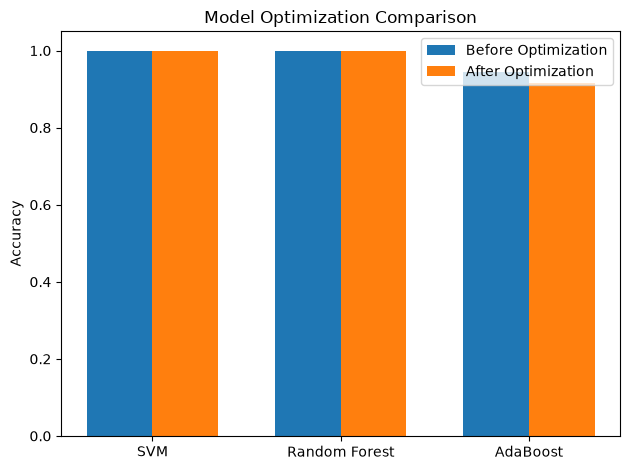

Model optimization completed!


In [41]:

# PR11: Advanced Machine Learning and Model Optimization
# Algorithms: SVM, Random Forest, and AdaBoost
# Optimization technique: Grid Search with Cross-Validation

import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score
import numpy as np

# Step 1: Load the Wine dataset
data = load_wine()
X = data.data
y = data.target

# Step 2: Split the data into training and testing sets
# 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 3: Create the three machine learning models
# StandardScaler is used for SVM because it is sensitive to feature scales
models = [
    make_pipeline(StandardScaler(), SVC()),
    RandomForestClassifier(random_state=42),
    AdaBoostClassifier(random_state=42)
]

# Step 4: Define the parameter combinations to test
# For a pipeline, use the step name followed by double underscores
parameters = [
    {
        "svc__C": [1, 10],
        "svc__kernel": ["linear", "rbf"]
    },
    {
        "n_estimators": [50, 100],
        "max_depth": [None, 5]
    },
    {
        "n_estimators": [50, 100],
        "learning_rate": [0.5, 1.0]
    }
]

# Names used in output and graph
names = ["SVM", "Random Forest", "AdaBoost"]

# Lists to store accuracy before and after optimization
before = []
after = []

# Step 5: Train and evaluate each model
for i in range(len(models)):

    model = models[i]

    # Train the original model
    model.fit(X_train, y_train)

    # Predict the classes of the test data
    prediction = model.predict(X_test)

    # Calculate accuracy before optimization
    accuracy = accuracy_score(y_test, prediction)
    before.append(accuracy)

    print(names[i], "Accuracy Before:", accuracy)

    # Step 6: Find the best parameters using Grid Search
    # Five-fold cross-validation is performed on training data
    grid = GridSearchCV(
        model,
        parameters[i],
        cv=5,
        scoring="accuracy"
    )
    grid.fit(X_train, y_train)

    # Get the best model selected by cross-validation
    best_model = grid.best_estimator_

    # Evaluate the optimized model on the test data
    prediction = best_model.predict(X_test)
    accuracy = accuracy_score(y_test, prediction)
    after.append(accuracy)

    print("Best Parameters:", grid.best_params_)
    print("Best Cross-Validation Accuracy:", grid.best_score_)
    print("Accuracy After:", accuracy)
    print()

# Step 7: Compare accuracy before and after optimization
x = np.arange(len(names))
width = 0.35

plt.bar(
    x - width / 2,
    before,
    width,
    label="Before Optimization"
)
plt.bar(
    x + width / 2,
    after,
    width,
    label="After Optimization"
)

plt.xticks(x, names)
plt.ylabel("Accuracy")
plt.title("Model Optimization Comparison")
plt.legend()
plt.tight_layout()
plt.show()

print("Model optimization completed!")
